# 05 – Karşılaştırma
Üç yöntemin (VADER, BERT, LLM) iki dildeki (İngilizce, Türkçe) sonuçlarını aynı ölçütlerle karşılaştırır.

**Girdiler:** `results/preds_<yöntem>_<dil>.csv` (6 dosya: vader, bert, llm × en, tr); ek deney için `results/preds_vader_tr_ham.csv`
**Çıktılar:** `results/karsilastirma_metrikler.csv`, `results/karsilastirma_hatalar.csv`, `results/figures/karsilastirma_metrikler.png`, `results/figures/cm_hepsi.png`
**Ortam:** Yerel Python 3.12; Drive gerekmez, repo klasöründen çalışır (`KOK = '..'`).

## 1. Altı tahmin dosyasının değerlendirilmesi
Altı dosya da ortak `src/evaluate.py` fonksiyonuyla ölçülür, böylece üç yöntemin sayıları aynı şekilde hesaplanır. Her dosyanın confusion matrix görseli `results/figures/` altına yeniden kaydedilir. Tablo accuracy, macro-F1 ve geçersiz cevap sayısını gösterir.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

KOK = '..'
sys.path.append(f'{KOK}/src')
from evaluate import evaluate, ETIKETLER

YONTEMLER = ['vader', 'bert', 'llm']
DILLER = ['en', 'tr']

sonuclar = []
for yontem in YONTEMLER:
    for dil in DILLER:
        s = evaluate(f'{KOK}/results/preds_{yontem}_{dil}.csv', gorsel_klasoru=f'{KOK}/results/figures')
        s['yontem'] = yontem.upper()
        s['dil'] = dil.upper()
        sonuclar.append(s)

metrikler = pd.DataFrame(sonuclar)[['yontem', 'dil', 'n', 'accuracy', 'macro_f1', 'gecersiz']]
metrikler

,yontem,dil,n,accuracy,macro_f1,gecersiz
0,VADER,EN,3000,0.5580,0.5368,0
1,VADER,TR,3000,0.6787,0.6759,0
2,BERT,EN,3000,0.7803,0.7752,0
3,BERT,TR,3000,0.9473,0.9472,0
4,LLM,EN,3000,0.7983,0.7935,2
5,LLM,TR,3000,0.7813,0.7856,23


## 2. Sınıf bazlı hata tablosu
Her yöntem, dil ve sınıf için hatalı tahmin sayısı (3 yöntem × 2 dil × 3 sınıf). Hata, o sınıfa ait olup yanlış tahmin edilen örnek sayısıdır; her sınıfta 1.000 örnek vardır.

In [2]:
satirlar = []
for s in sonuclar:
    for etiket in ETIKETLER:
        satirlar.append({'yontem': s['yontem'], 'dil': s['dil'], 'sinif': etiket, 'hata': s['hatalar'][etiket]})

hatalar = pd.DataFrame(satirlar).pivot_table(index='yontem', columns=['dil', 'sinif'], values='hata')
hatalar = hatalar.reindex(index=['VADER', 'BERT', 'LLM'], columns=pd.MultiIndex.from_product([['EN', 'TR'], ETIKETLER]))
hatalar = hatalar.astype(int)
hatalar

EN                   TR             
       Pozitif Negatif Nötr Pozitif Negatif Nötr
yontem                                          
VADER       91     567  668     178     455  331
BERT       129     134  396      47     111    0
LLM        121     106  378     200     249  207

## 3. Tabloları kaydetme
Metrik tablosu `results/karsilastirma_metrikler.csv`, hata tablosu `results/karsilastirma_hatalar.csv` dosyasına yazılır. Rapordaki tablolar bu dosyalardan alınmıştır.

In [3]:
metrikler.to_csv(f'{KOK}/results/karsilastirma_metrikler.csv', index=False, encoding='utf-8')
hatalar.to_csv(f'{KOK}/results/karsilastirma_hatalar.csv', encoding='utf-8')
print('Kaydedildi')

Kaydedildi


## 4. Accuracy ve macro-F1 grafiği
Accuracy ve macro-F1 değerleri yöntem ve dile göre yan yana çubuklarla gösterilir. Grafik `results/figures/karsilastirma_metrikler.png` olarak kaydedilir.

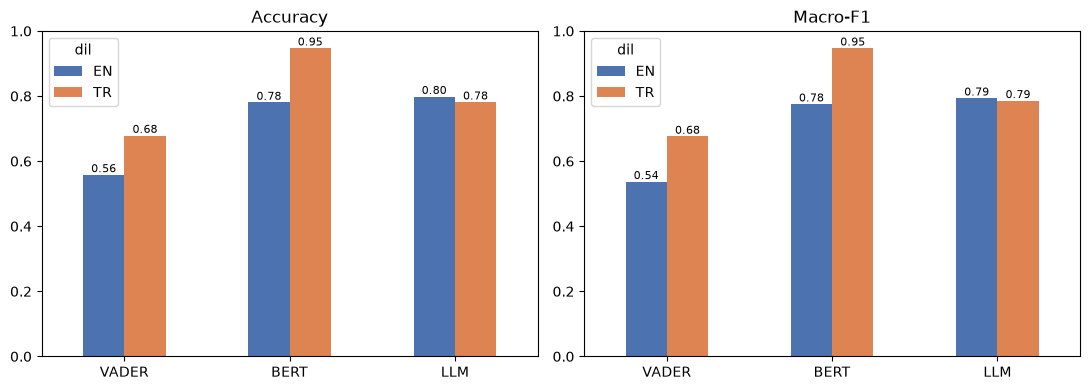

In [4]:
fig, eksenler = plt.subplots(1, 2, figsize=(11, 4))

for eksen, metrik, baslik in zip(eksenler, ['accuracy', 'macro_f1'], ['Accuracy', 'Macro-F1']):
    tablo = metrikler.pivot(index='yontem', columns='dil', values=metrik).reindex(['VADER', 'BERT', 'LLM'])
    tablo.plot(kind='bar', ax=eksen, rot=0, ylim=(0, 1), color=['#4C72B0', '#DD8452'])
    eksen.set_title(baslik)
    eksen.set_xlabel('')
    for kap in eksen.containers:
        eksen.bar_label(kap, fmt='%.2f', fontsize=8)

plt.tight_layout()
plt.savefig(f'{KOK}/results/figures/karsilastirma_metrikler.png', dpi=150)
plt.show()

## 5. Confusion matrix'ler
Altı confusion matrix tek görselde gösterilir: üst satır İngilizce, alt satır Türkçe. Her matriste satırlar gerçek, sütunlar tahmin edilen sınıftır. Görsel `results/figures/cm_hepsi.png` olarak kaydedilir.

> **Not:** LLM matrislerinde bazı satır toplamları 1.000'den azdır, çünkü "Geçersiz" cevaplar (EN 2, TR 23) matriste gösterilmez. Bu cevaplar hatalı tahmin olarak sayılmıştır.

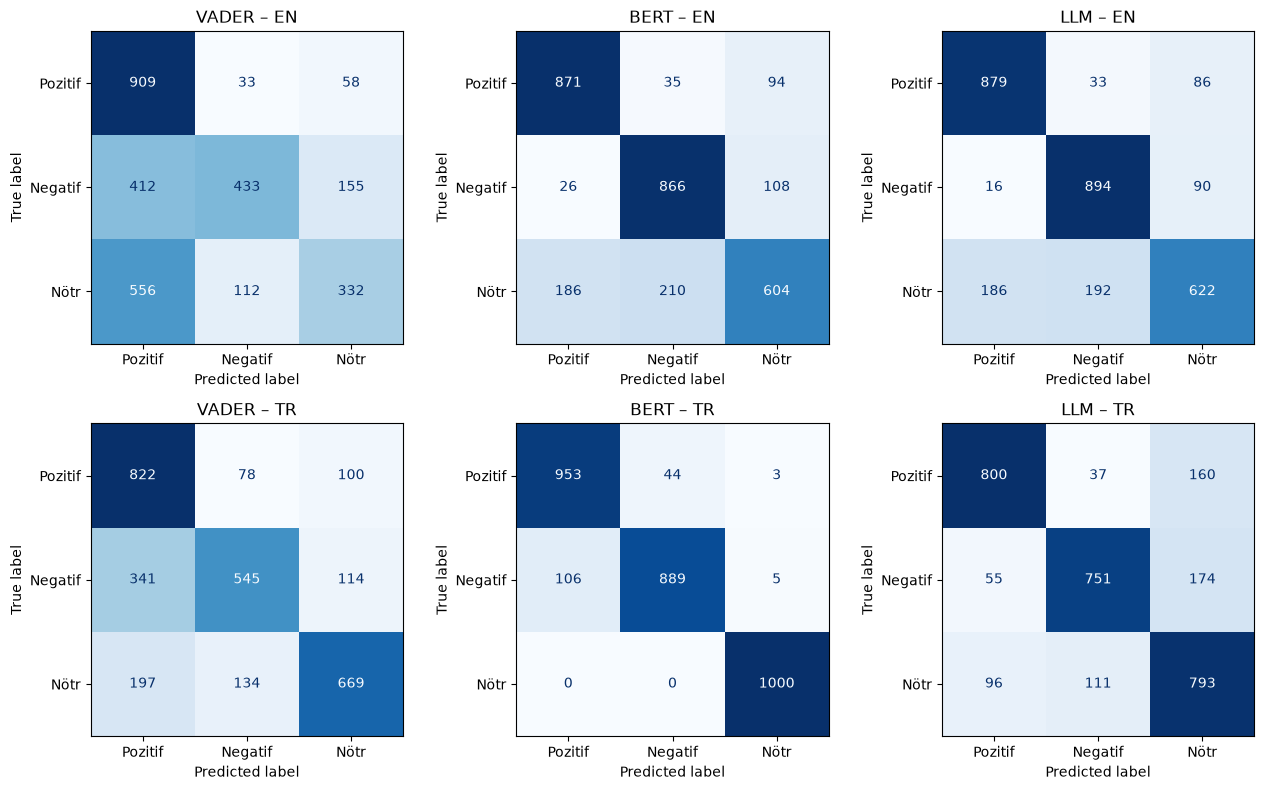

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, eksenler = plt.subplots(2, 3, figsize=(13, 8))

for j, yontem in enumerate(YONTEMLER):
    for i, dil in enumerate(DILLER):
        df = pd.read_csv(f'{KOK}/results/preds_{yontem}_{dil}.csv')
        cm = confusion_matrix(df['true'], df['pred'], labels=ETIKETLER)
        ConfusionMatrixDisplay(cm, display_labels=ETIKETLER).plot(
            ax=eksenler[i, j], cmap='Blues', values_format='d', colorbar=False)
        eksenler[i, j].set_title(f'{yontem.upper()} – {dil.upper()}')

plt.tight_layout()
plt.savefig(f'{KOK}/results/figures/cm_hepsi.png', dpi=150)
plt.show()

## 6. Ek deney: çeviri adımının katkısı
Türkçe VADER'ın çevirili ve çevirisiz (ham) sonuçları karşılaştırılır. Çeviri adımı accuracy'yi yaklaşık 0,36'dan 0,68'e çıkarır.

In [6]:
ham = evaluate(f'{KOK}/results/preds_vader_tr_ham.csv', gorsel_klasoru=f'{KOK}/results/figures')
ceviri = metrikler[(metrikler['yontem'] == 'VADER') & (metrikler['dil'] == 'TR')].iloc[0]

print(f"VADER TR ham (çevirisiz):  accuracy {ham['accuracy']:.4f}  macro-F1 {ham['macro_f1']:.4f}")
print(f"VADER TR çeviri + VADER:   accuracy {ceviri['accuracy']:.4f}  macro-F1 {ceviri['macro_f1']:.4f}")
print(f"Çevirinin katkısı:         accuracy +{ceviri['accuracy'] - ham['accuracy']:.4f}  macro-F1 +{ceviri['macro_f1'] - ham['macro_f1']:.4f}")

VADER TR ham (çevirisiz):  accuracy 0.3640  macro-F1 0.2324
VADER TR çeviri + VADER:   accuracy 0.6787  macro-F1 0.6759
Çevirinin katkısı:         accuracy +0.3147  macro-F1 +0.4435
